In [1]:
#!/usr/bin/env python3


from __future__ import print_function, division
from collections import defaultdict, OrderedDict
import gzip
import pickle
import json
import os
import uproot
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
from coffea import hist, processor 
from coffea.hist import plot
from coffea.util import load, save

In [2]:
hists = load('../../../hists/UL_lep_monotop_v1_test_2018.scaled')
data={
    '2018':{
        'sre': 'EGamma',
        'srm': 'SingleMuon',
        'wjetm': 'SingleMuon',
        'ttbarm': 'SingleMuon',
        'wjete': 'EGamma',
        'ttbare': 'EGamma',
#         'zmcr': 'MET',
#         'zecr': 'EGamma',
#         'gcr': 'EGamma'
    }
}

data_hists   = hists['data']
bkg_hists    = hists['bkg']
signal_hists = hists['sig']

In [18]:
data_hists['template'].identifiers('process',)

[<StringBin (SingleMuon) instance at 0x7f260eb17978>,
 <StringBin (EGamma) instance at 0x7f260eb17b00>]

In [23]:
bkg_hists['template'].integrate('region', 'wjete').values()

{('DY+HF',
  'nominal'): array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  4.52331147e+00,
         4.93679512e+01,  2.82018571e+01,  1.58770795e+01,  1.67300804e+01,
         1.98973675e+01,  6.62812116e+00,  1.15940439e-02, -4.28570297e-02,
        -4.46769887e-02, -3.44446644e-02,  7.83882824e-02, -4.95661506e-01,
        -4.78423244e-03, -9.25180168e-03,  4.16283131e-02,  0.00000000e+00]),
 ('DY+HF',
  'btagUp'): array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  4.52331147e+00,
         4.93679512e+01,  2.82018571e+01,  1.58770795e+01,  1.67300804e+01,
         1.98973675e+01,  6.62812116e+00,  1.15940439e-02, -4.28570297e-02,
        -4.46769887e-02, -3.44446644e-02,  7.83882824e-02, -4.95661506e-01,
        -4.78423244e-03, -9.25180168e-03,  4.16283131e-02,  0.00000000e+00]),
 ('DY+HF',
  'btagDown'): array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  4.52331147e+00,
         4.93679512e+01,  2.82018571e+01,  1.58770795e+01,  1.67300804e+01,
         1.9

In [26]:
bkg_hists['template'].integrate('region', 'wjete')

<Hist (process,systematic,mT_corrected) instance at 0x7f062947bda0>

In [26]:
def RebinHist(histogram, axisName, rebinN=1):
    old_axis = histogram.axis(axisName)
    new_axis = hist.Bin(old_axis.name, old_axis.label, old_axis.edges()[::rebinN])
    return histogram.rebin(axisName, new_axis)

In [27]:
def SetRangeHist(histogram, axisName, lower_bound=None, upper_bound=None):
    old_axis = histogram.axis(axisName)
    lower_idx, upper_idx = None, None
    if not lower_bound is None:
        lower_idx = np.where(old_axis.edges() >= lower_bound)[0][0]
    if not upper_bound is None:
        upper_idx = np.where(old_axis.edges() <= upper_bound)[0][-1] + 1

    new_axis = hist.Bin(
        old_axis.name, old_axis.label, old_axis.edges()[lower_idx:upper_idx]
    )
    return histogram.rebin(axisName, new_axis)

In [34]:
data_hists['template'].integrate('region', "wjete").integrate("systematic").sum('process').to_hist()

Hist(Regular(20, 0, 600, name='mT_corrected', label='$m_{T}$ [GeV] Corrected'), storage=Weight()) # Sum: WeightedSum(value=153594, variance=153594) (WeightedSum(value=153880, variance=153880) with flow)

In [4]:
data_hists['template'].integrate('region', 'ttbare').integrate('systematic').values()

{('EGamma',): array([0.000e+00, 0.000e+00, 0.000e+00, 9.027e+03, 8.669e+03, 5.587e+03,
        3.292e+03, 1.874e+03, 1.121e+03, 6.130e+02, 3.490e+02, 2.340e+02,
        1.280e+02, 7.500e+01, 5.000e+01, 2.400e+01, 2.900e+01, 1.700e+01,
        1.100e+01, 5.000e+00])}

In [16]:
signal_hists['template'].integrate('region', _region).integrate('systematic', _systematic).sum('npvs').values()

{('Mphi-1995_Mchi-1000',): array([ 0.        ,  0.        ,  0.        , 14.40902779, 23.2471321 ,
        22.53523013, 43.57214412, 27.95441782, 50.4832799 , 43.47475553,
        29.43962001, 30.26929864, 18.89923345, 33.13042462, 40.41548333,
        26.86421799,  9.75527219, 17.61160599, 14.33038557,  0.68343492]),
 ('Mphi-2000_Mchi-1500',): array([ 0.        ,  0.        ,  0.        , 14.25921353, 17.88607783,
        44.51077986, 42.11253796, 19.84586479, 63.09928967, 46.23974223,
        32.34145477, 50.20240197, 35.73080084, 29.90662947, 24.72754715,
        25.91486739, 28.63530943, 10.62675331, 18.46703159, 15.14232055]),
 ('Mphi-2000_Mchi-500',): array([ 0.        ,  0.        ,  0.        , 20.68767031, 23.65760766,
        30.96787941, 30.18850108, 59.40757373, 43.64921278, 48.39739288,
        32.90787239, 29.70843023, 29.41504956, 27.56962706, 29.11422787,
         9.03229968, 16.48440946, 22.08201103, 18.63619562, 12.0435638 ])}

In [34]:
signal_hists['template'].identifiers("process")

[<StringBin (Mphi-1995_Mchi-1000) instance at 0x7f0f38305320>,
 <StringBin (Mphi-2000_Mchi-1500) instance at 0x7f0f38305358>,
 <StringBin (Mphi-2000_Mchi-500) instance at 0x7f0f38305390>]

In [37]:
str_ = str("Mphi-1995_Mchi-1000")

In [38]:
str_.replace('-', "_")

'Mphi_1995_Mchi_1000'

In [72]:
for signal in signal_hists['template'].identifiers("process"):
    for _region in bkg_hists['template'].identifiers("region"):
    #     print(_region)
        str_signal = str(signal).replace('-', "_")
        outdir = "RootFiles"
        if not os.path.exists(outdir):
            os.makedirs(outdir)
        outputFile = uproot.recreate(os.path.join(outdir, str(_region)+"_mT_Output_"+str_signal+"_.root"))
        outputFile["dataObs"] = data_hists['template'].integrate('region', _region).integrate("systematic").sum('process').sum('npvs').to_hist()
        for _process in bkg_hists['template'].identifiers("process"):
            for _systematic in bkg_hists['template'].identifiers("systematic"):
                if  _systematic not in bkg_hists['template'].integrate('region', _region).integrate('process', _process).identifiers("systematic"):
                    continue
                outputFile[f"{_process}_{_systematic}"] = bkg_hists['template'].integrate('process', _process).integrate('region', _region).integrate("systematic", _systematic).sum("npvs").to_hist()

        for _process in signal_hists['template'].identifiers("process"):
            if signal != _process: continue
            for _systematic in signal_hists['template'].identifiers("systematic"):
#                 print(_systematic)
                if  _systematic not in signal_hists['template'].integrate('region', _region).integrate('process', _process).identifiers("systematic"):
                    continue
                outputFile[f"{_process}_{_systematic}"] = signal_hists['template'].integrate('process', _process).integrate('region', _region).integrate("systematic", _systematic).sum("npvs").to_hist()
    #         print(signal_hists['template'].integrate('process', _process).integrate('region', _region).integrate("systematic", _systematic).sum("npvs").values())            
    outputFile.close()

In [12]:
data_hists['template'].integrate('region', 'ttbare').integrate("systematic").sum('npvs').sum('process').values()

{(): array([0.000e+00, 0.000e+00, 0.000e+00, 9.014e+03, 8.648e+03, 5.577e+03,
        3.289e+03, 1.873e+03, 1.117e+03, 6.100e+02, 3.480e+02, 2.350e+02,
        1.280e+02, 7.500e+01, 5.000e+01, 2.400e+01, 2.900e+01, 1.700e+01,
        1.100e+01, 5.000e+00])}

In [9]:
bkg_hists['template'].integrate('process', "W+HF").integrate('region', 'ttbare').integrate("systematic", 'btagUp').sum("npvs").values()

{(): array([ 0.00000000e+00,  0.00000000e+00,  0.00000000e+00,  1.59979839e+02,
         1.42154529e+02,  3.89530687e+01,  5.50715995e+00,  8.55872690e+00,
         2.39533329e+00,  1.07028634e+01,  8.10148284e+00,  8.16912996e+00,
         4.34732611e-01,  5.76113234e-01,  5.46034465e-01,  2.02380817e-01,
         1.32701579e-01,  3.63659067e-01, -4.72558851e-02,  0.00000000e+00])}

In [29]:
_region =  'wjete'
for _process in signal_hists['template'].identifiers("process"):
    for _systematic in signal_hists['template'].identifiers("systematic"):
        print(_systematic)
        if  _systematic not in signal_hists['template'].integrate('region', _region).integrate('process', _process).identifiers("systematic"):
            continue
#         outputFile[f"{_process}_{_systematic}"] = signal_hists['template'].integrate('process', _process).integrate('region', _region).integrate("systematic", _systematic).sum("npvs").to_hist()
        print(signal_hists['template'].integrate('process', _process).integrate('region', _region).integrate("systematic", _systematic).sum("npvs").values())

btagDown
{(): array([ 0.        ,  0.        ,  0.        ,  5.99846804, 17.64711202,
       27.7970697 , 24.3748116 , 24.61502881, 23.76643209, 26.12864676,
       13.77931138, 19.1123347 , 15.11606687,  9.57042485,  8.23314554,
        9.91513573, 10.25098786,  6.36854987,  6.98792837,  5.47331245])}
btagUp
{(): array([ 0.        ,  0.        ,  0.        ,  5.99846804, 17.64711202,
       27.7970697 , 24.3748116 , 24.61502881, 23.76643209, 26.12864676,
       13.77931138, 19.1123347 , 15.11606687,  9.57042485,  8.23314554,
        9.91513573, 10.25098786,  6.36854987,  6.98792837,  5.47331245])}
id_eDown
{(): array([ 0.        ,  0.        ,  0.        ,  5.89682521, 17.32258936,
       27.07781263, 23.74502218, 23.85379142, 23.286999  , 25.07578118,
       13.3627727 , 18.88190341, 14.78757584,  9.49542367,  8.0525029 ,
        9.83810926,  9.90687737,  6.22656232,  6.83245208,  5.24359508])}
id_eUp
{(): array([ 0.        ,  0.        ,  0.        ,  6.10011087, 17.97163467,
      

{(): array([ 0.        ,  0.        ,  0.        ,  5.73543547, 17.97748624,
       25.18800451, 27.99370056, 28.43523921, 26.34101115, 22.04844013,
       22.09039978, 16.40144805, 13.41900669, 10.01181561, 11.32520308,
        9.65778087,  5.79538626,  5.49113147,  4.56629702,  5.97264467])}
id_eDown
{(): array([ 0.        ,  0.        ,  0.        ,  5.61960719, 17.52863608,
       24.58936632, 27.57117167, 27.87127732, 25.67329409, 21.35892652,
       21.35086672, 16.16275382, 13.09780323,  9.79453797, 10.85359133,
        9.57118413,  5.67155226,  5.35878889,  4.46687113,  5.85011277])}
id_eUp
{(): array([ 0.        ,  0.        ,  0.        ,  5.85126375, 18.42633641,
       25.7866427 , 28.41622945, 28.9992011 , 27.00872821, 22.73795374,
       22.82993284, 16.64014228, 13.74021015, 10.22909325, 11.79681483,
        9.74437761,  5.91922025,  5.62347406,  4.6657229 ,  6.09517657])}
id_mDown
id_mUp
isolation_eDown
{(): array([ 0.        ,  0.        ,  0.        ,  5.73543547, 17.

In [73]:
import ROOT
f1 = ROOT.TFile.Open('RootFiles/ttbare_mT_Output_Mphi_1995_Mchi_1000_.root')
h = f1.Get('dataObs')
c1 = ROOT.TCanvas()
h.Draw('E') # for TGraphErrors
c1.Print('dataObs.png')

Info in <TCanvas::Print>: png file dataObs.png has been created


In [76]:
f2 = ROOT.TFile.Open('../../ControlRegionModel_wjete/ControlRegionModel.root')
RooWorkspace *wspace = (RooWorkspace*) f2->Get("w")

SyntaxError: invalid syntax (<ipython-input-76-90c7642eec54>, line 2)

In [1]:
!pwd

/cms/scratch/runiyal/new_coffea/decaf/analysis/Rishabh_NB/new_coffea_nbs/Combine_related


In [2]:
import ROOT
f1 = ROOT.TFile.Open('test_combine/ControlRegionModel.root')
# h = f1.Get('dataObs')
# c1 = ROOT.TCanvas()
# h.Draw('E') # for TGraphErrors
# c1.Print('dataObs.png')

Welcome to JupyROOT 6.18/00


In [4]:
f1.ls()

TFile**		test_combine/ControlRegionModel.root	
 TFile*		test_combine/ControlRegionModel.root	
  KEY: RooWorkspace	ControlRegionModel;1	ControlRegionModel
  KEY: TProcessID	ProcessID0;1	784dc0ca-cc5d-11ec-bf95-797c4b86beef


NameError: name 'h' is not defined

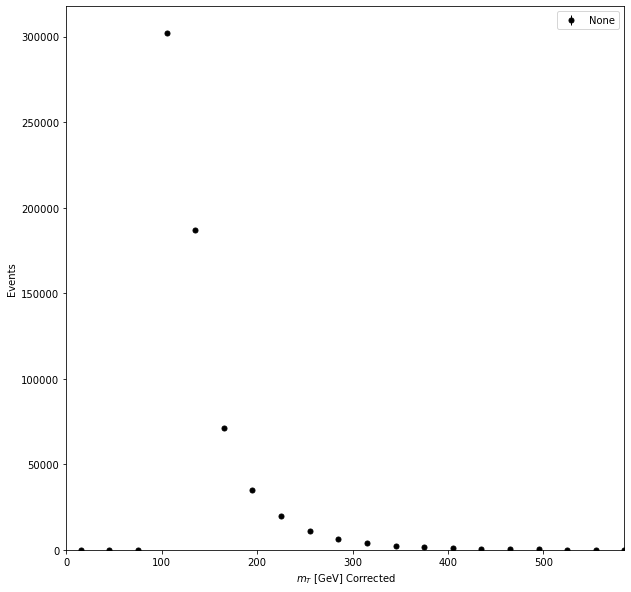

In [9]:
from coffea.hist import plot
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,1, figsize=(10,10))
fill_opts = {'edgecolor': (0,0,0,0.3), 'alpha': 1}
error_opts = {'label':'Stat. Unc.', 'hatch':'///', 'facecolor':'none', 'edgecolor':(0,0,0,.5), 'linewidth': 0}
nostack_fill_opts = {'alpha': 0.2, 'label': '_nolabel_'}
data_err_opts = {'linestyle':'None', 'marker': '.', 'markersize': 10., 'color':'k'}#, 'elinewidth': 1, 'emarker': '_'}
#colors = ['#a6cee3','#1f78b4','#b2df8a','#33a02c','#fb9a99','#e31a1c']
colors = ['#a6cee3', '#3130db', '#1f78b4', '#b2df8a', '#48e926', '#33a02c', '#c0df26',
                  '#fb9a99', '#d02ba7', '#e31a1c', '#fdbf6f', '#ff7f00', '#cab2d6', '#c64bc4',
                  '#6a3d9a', '#a9ce26', '#ffff99', '#b15928', '#edcc43']
plot.plot1d(hData,  
        ax=ax,
        clear=False,
           error_opts=data_err_opts,
           )

plot.plot1d(h.integrate('systematic', 'nominal'),  
            overlay='process',
        ax=ax,
        clear=False,
            stack=True, 
#            error_opts=error_opts,
           )
ax._get_lines.prop_cycler = ax._get_patches_for_fill.prop_cycler
args = {'linestyle':'--', 'linewidth': 5}
ax.autoscale(axis='x', tight=True)
# ax.set_yscale('log')
# if(key=='dilepmass'): ax.set_xlim(50, 130)
ax.set_ylim(.1, None)
ax.autoscale()
leg = ax.legend(ncol=2, loc='best')




In [15]:
h.axis("process").identifiers()

NameError: name 'h' is not defined

In [13]:
f = uproot.open("RootFiles/ttbare/mT_Output.root")

In [14]:
f.keys()

['dataObs;1',
 'DY+HF_btagDown;1',
 'DY+HF_btagUp;1',
 'DY+HF_ew1Down;1',
 'DY+HF_ew1Up;1',
 'DY+HF_ew2GDown;1',
 'DY+HF_ew2GUp;1',
 'DY+HF_ew2WDown;1',
 'DY+HF_ew2WUp;1',
 'DY+HF_ew2ZDown;1',
 'DY+HF_ew2ZUp;1',
 'DY+HF_ew3GDown;1',
 'DY+HF_ew3GUp;1',
 'DY+HF_ew3WDown;1',
 'DY+HF_ew3WUp;1',
 'DY+HF_ew3ZDown;1',
 'DY+HF_ew3ZUp;1',
 'DY+HF_id_eDown;1',
 'DY+HF_id_eUp;1',
 'DY+HF_isolation_eDown;1',
 'DY+HF_isolation_eUp;1',
 'DY+HF_mixDown;1',
 'DY+HF_mixUp;1',
 'DY+HF_muFDown;1',
 'DY+HF_muFUp;1',
 'DY+HF_muRDown;1',
 'DY+HF_muRUp;1',
 'DY+HF_nominal;1',
 'DY+HF_pileupDown;1',
 'DY+HF_pileupUp;1',
 'DY+HF_qcd1Down;1',
 'DY+HF_qcd1Up;1',
 'DY+HF_qcd2Down;1',
 'DY+HF_qcd2Up;1',
 'DY+HF_qcd3Down;1',
 'DY+HF_qcd3Up;1',
 'DY+HF_reco_eDown;1',
 'DY+HF_reco_eUp;1',
 'DY+HF_trig_eDown;1',
 'DY+HF_trig_eUp;1',
 'DY+LF_btagDown;1',
 'DY+LF_btagUp;1',
 'DY+LF_ew1Down;1',
 'DY+LF_ew1Up;1',
 'DY+LF_ew2GDown;1',
 'DY+LF_ew2GUp;1',
 'DY+LF_ew2WDown;1',
 'DY+LF_ew2WUp;1',
 'DY+LF_ew2ZDown;1',
 'DY+LF_e